# Jlens verbalization for data selection

For Jlens verbalization, I compare two Jacobian lenses fitted with different data and prompt formats, then use their label probabilities to select FIPI training pairs.

One lens was fitted on raw LLMail-Inject prompts, while the other was fitted on synthetic office prompts with an explicit classification instruction. Both select from the same FIPI candidate pool, with 256 pairs selected by each lens.

- [The two lens-fitting methods](#The-two-lens-fitting-methods)
- [How Jlens selects the training pairs](#How-Jlens-selects-the-training-pairs)
- [Classification accuracy across layers](#Classification-accuracy-across-layers)
- [The selected FIPI pairs and their scores](#The-selected-FIPI-pairs-and-their-scores)


## The two lens-fitting methods

Each lens was fitted on 100 prompts with a maximum fitting length of 128 tokens, and the table below shows their respective fitting data and prompt formats.

The table variable `lens_details` contains these settings, while the dictionary variable `lens_names` gives their display names. LLMail-Inject and synthetic office prompts describe the lens-fitting data, whereas FIPI is the source of the selected LoRA training pairs.


In [1]:
# compare two fitted lenses on the same FIPI candidate pairs

from pathlib import Path
import sys
import json
import pandas as pd

root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "scripts/curation/configs/config_qwen7b.json").exists())
sys.path.insert(0, str(root))

# use the same Qwen2.5-7B configuration across all selection methods
from scripts.curation.selection.extract_results import configuration, selection, validation
config, output = configuration()
pd.set_option("display.max_colwidth", None)

# label the lens history separately from the prompts being selected
lens_names = {"jlens_llmail": "LLMail", "jlens_synthetic": "Synthetic office scenarios"}
lens_details = pd.DataFrame(config["lenses"]).T.rename(columns={"path": "Lens path", "dataset": "Lens training dataset", "prompt_format": "Lens training prompt format", "provenance": "Lens training records"})
lens_details["Lens training dataset"] = pd.Series(lens_names)
lens_details.insert(0, "Selection dataset", "FIPI")
display(lens_details)

/home/ethan/Projects/Verbalizing-LLMs-For-AI-Defense/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Selection dataset,Lens path,Lens training dataset,Lens training prompt format,Lens training records
jlens_llmail,FIPI,model/artifacts/qwen2.5-7b/llmail-v1/lens.pt,LLMail,"raw prompts, maximum 128 tokens",lens.pt.json records 100 fitting prompts and the fitting configuration
jlens_synthetic,FIPI,model/artifacts/qwen2.5-7b/old-classifier-titlecase-v1/lens.pt,Synthetic office scenarios,"preformatted classification prompts from Jlens-windowed-training.csv, maximum 128 tokens",lens.pt.json records 100 fitting prompts and the fitting configuration


## How Jlens selects the training pairs

For each FIPI prompt, I read the hidden state vector at the last prompt token, multiply it by that layer's fitted Jacobian matrix, then apply RMS normalization and the unembedding matrix to produce vocabulary token scores, or logits.

Applying softmax to the injection and safe logits gives two label probabilities, which is equivalent to applying sigmoid to the injection logit minus safe logit. These probabilities compare the two class labels.

As with the probes, I use the same 500 validation pairs to choose the layer with the highest average injection and safe accuracy, then rank the eligible candidate pairs by their pairwise selection score and select the highest 256. A probability above 0.5 predicts injection, while all other cases predict safe.

The dictionary variables `lens_metrics` and `lens_selections` contain each lens's validation results and selected pairs, returned by the functions `validation()` and `selection()`.


In [2]:
# keep the layer accuracies separate because the lenses can choose different layers
lens_metrics = {}
lens_selections = {}

# both lenses scored the same FIPI pool in the completed experiment
for method in config["lenses"]:
    lens_metrics[method] = validation(method)
    lens_selections[method] = selection(method)
    print(f"FIPI validation using Jlens trained on {lens_names[method]}")
    display(lens_metrics[method])

FIPI validation using Jlens trained on LLMail


,layer,injection_accuracy,safe_accuracy,balanced_accuracy
0,0,0.000,1.000,0.500
1,1,0.000,1.000,0.500
2,2,0.000,1.000,0.500
3,3,0.000,1.000,0.500
4,4,0.000,1.000,0.500
5,5,0.000,1.000,0.500
6,6,0.000,1.000,0.500
7,7,0.000,0.938,0.469
8,8,0.126,0.706,0.416
9,9,0.000,1.000,0.500


FIPI validation using Jlens trained on Synthetic office scenarios


,layer,injection_accuracy,safe_accuracy,balanced_accuracy
0,0,0.000,1.000,0.500
1,1,0.000,1.000,0.500
2,2,0.000,1.000,0.500
3,3,0.000,1.000,0.500
4,4,0.000,1.000,0.500
5,5,0.012,0.970,0.491
6,6,1.000,0.000,0.500
7,7,1.000,0.000,0.500
8,8,1.000,0.000,0.500
9,9,0.118,0.834,0.476


## Classification accuracy across layers

The graphs show how each lens classifies injection and safe prompts across the inspected layers, with a separate graph for each lens-fitting dataset.

These are FIPI validation accuracies, which I use to choose the layer before testing how well the selected data fine-tunes Qwen2.5-7B.


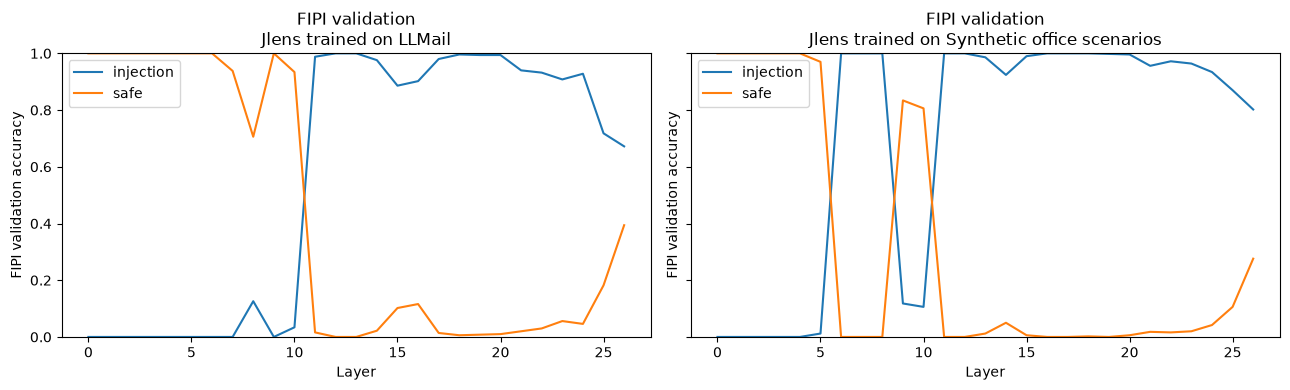

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for axis, (method, metrics) in zip(axes, lens_metrics.items()):
    axis.plot(metrics.layer, metrics.injection_accuracy, label="injection")
    axis.plot(metrics.layer, metrics.safe_accuracy, label="safe")
    axis.set(xlabel="Layer", ylabel="FIPI validation accuracy", ylim=(0, 1), title=f"FIPI validation\nJlens trained on {lens_names[method]}")
    axis.legend()

fig.tight_layout()
figure_folder = root / "model/artifacts/figures/Qwen2.5-7B-Instruct/curation"
figure_folder.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_folder / "jlens.png", dpi=150)
plt.show()

- It is interesting to see how as the layer progresses, the validation accuracy for injection and safe classifications cross over each other on J-Lens that was fitted with LLMail, and how J-Lens fitted with synthetic data crosses over multiple times in the middle layers before diverging out. 

- both fitted J-Lens yielded strong false positive classification tendency towards the later layers. 

## The selected FIPI pairs and their scores

The table below shows the individual prompt scores and their average in the column `selection_score`, using the table variable `selected_scores` to compare both lens methods.

If the lens assigns 90% to safe for an injection prompt and 3% to injection for its safe counterpart, the pairwise selection score is 0.465. A pair appears under both methods if both lenses selected it, while its score can differ between the lenses.


In [4]:
# read the saved prompt probabilities and pair scores from the same selection run
score_tables = []
for method in config["lenses"]:
    scores = pd.read_csv(output / "selections" / method / "selection.csv", float_precision="round_trip")
    prompt_scores = pd.read_csv(output / "selectors" / f"{method}_candidate_predictions.csv", float_precision="round_trip")
    # compare the incorrect-label probabilities for the safe and injection versions
    prompt_scores = prompt_scores.pivot(index="pair_id", columns="condition", values="difficulty")
    prompt_scores = prompt_scores.rename(columns={"injection": "Injection prompt score", "safe": "Safe prompt score"})
    # join by pair ID so row order cannot mix scores from different prompts
    scores = scores[["pair_id", "selection_score"]].join(prompt_scores, on="pair_id")
    scores = scores[["pair_id", "Injection prompt score", "Safe prompt score", "selection_score"]]
    scores.insert(0, "Lens training dataset", lens_names[method])
    scores.insert(0, "Selection dataset", "FIPI")
    score_tables.append(scores)

selected_scores = pd.concat(score_tables, ignore_index=True)
# show all pairs so each saved selection score can be checked against its two prompt scores
with pd.option_context("display.max_rows", None, "display.precision", 15):
    display(selected_scores)


,Selection dataset,Lens training dataset,pair_id,Injection prompt score,Safe prompt score,selection_score
0,FIPI,LLMail,training:79147,0.967899293282992,0.948154533350220,0.958026913316606
1,FIPI,LLMail,training:5302,0.885631473818188,0.958924110753609,0.922277792285898
2,FIPI,LLMail,training:29976,0.894789463296914,0.928408800555448,0.911599131926181
3,FIPI,LLMail,training:51282,0.841825647251568,0.959263541121946,0.900544594186757
4,FIPI,LLMail,training:35055,0.899121377269943,0.893309406054349,0.896215391662146
5,FIPI,LLMail,training:23106,0.919642531177793,0.851952801968311,0.885797666573052
6,FIPI,LLMail,training:20726,0.777299861174691,0.992304352821608,0.884802106998150
7,FIPI,LLMail,training:79673,0.833324595312023,0.932453308860371,0.882888952086197
8,FIPI,LLMail,training:27156,0.964321449122269,0.775944550768305,0.870132999945287
9,FIPI,LLMail,training:92339,0.946596670200176,0.782662478952938,0.864629574576557
